# UNSW kinetic-inductance parametric amplifier (KIPA, device BA13), topology rebuilt in the Quantcore PDK

**What it is.** A KIPA: a λ/4 CPW resonator of a high-kinetic-inductance film, shorted at one end and bounded at
the other by a stepped-impedance filter (SIF) — alternating low- and high-impedance λ/4 sections that act as a
Bragg mirror for the resonance while letting a DC bias through. DC + pump give three-wave mixing in the resonator.
In this device the shorted end is a 1 µm wire carrying the largest current density, under which bismuth donor
spins sit: the amplifier amplifies their echoes in situ (Vine et al., arXiv:2211.11333; the KIPA of Parker et al.,
PR Applied 17, 034064 (2022)).

**Source.** Zenodo 7600250 (CC BY 4.0), `BA13_device_gds.GDS` (one cell `DEVICE`; 0/0 die 4 × 11 mm, 7/0 and 8/0
wide / narrow centre conductors, 9/0 the 1 µm wire, 10/0 ground), downloaded into its own folder
`build/external/kipa_zenodo_7600250/` and only read. Measured from the GDS:

| section | centre / gap (µm) | length (µm) |
|---|---|---|
| feed | 100 / 45 | ≈ 1700 (with its taper) |
| SIF low-Z × 4 | 138 / 6 | ≈ 3400 |
| SIF high-Z × 3 | 10 / 70 | ≈ 3455 |
| resonator | 5 / 15 | ≈ 2981 |
| wire (spin region) | 1 / 10 | ≈ 1750, shorted to ground |

**This is a topology rebuild in the Quantcore PDK**: the same section sequence drawn with our routes (each section
a qcc route of its own width, joined by `CpweTaper`s), a `BondPad` on the south edge, the short as a route free end
(`term=0`), on our Nb film. The source film (NbTiN, strongly kinetic) is not stated in the GDS; the analysis runs on
the PDK Nb film. The rows are re-folded with 300 µm U-turns (the source's own serpentine is close to it).

## 1 · Setup and the PDK

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.analysis.synthesis import cpw_properties

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
RUN_FEM = False
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
show_md(pdk_facts_md(PDK))
SECTIONS = [("S0", 138, 6, 3400), ("S1", 10, 70, 3455), ("S2", 138, 6, 3400), ("S3", 10, 70, 3455),
            ("S4", 138, 6, 3400), ("S5", 10, 70, 3455), ("S6", 138, 6, 3394)]
RES, WIRE = (5, 15, 2981), (1, 10, 1750)

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

## 2 · The die and frame
The source die, 4 × 11 mm, with the Quantcore frame.

In [3]:
W, H = 4000, 11000
d = Designer("unsw_kipa", box=(0, 0, W, H), chip={"name_chip": "KIPA"}, live=LIVE)

## 3 · Pads (the 100 µm rule)
One `BondPad` on the south edge whose taper ends in the 100/45 µm feed (the source bonds straight onto the feed).

In [4]:
X_FEED = 1300                                    # clear of the south-west marker area (500 µm)
d.add("P_IN", "BondPad", at=(X_FEED, 300), rot=0, edge="auto", a=100, b=45, pad_width=400)

<BondPad P_IN ports=['a']>

## 4 · Components
The section boundaries are `CpweTaper`s (20 µm, from one section's a/b to the next): T0 feed → low-Z, T1…T6
between the SIF sections, T7 SIF → resonator, T8 resonator → wire. The rows are 600 µm apart; the taper positions
are solved so each route between two tapers (along a row, a 300 µm U-turn, back along the next row) has its
section's length.

In [5]:
X_L, X_R, R_TURN, PITCH = 470.0, 3530.0, 300.0, 600.0
Y0 = 9766.0 - 1000.0 - 7 * PITCH               # the wire sits at the source's height (y = 9.77 mm)
U = PITCH + np.pi * R_TURN - 4 * R_TURN          # a U-turn adds this to the two straights (two r = 300 µm bends)
xs = [2000.0]
for k, (_, _, _, length) in enumerate(SECTIONS):
    x = xs[-1]
    if k % 2 == 0:   # turn at the right end; the next row runs −x
        xs.append(2 * X_R - x - 20 + U - length)
    else:            # turn at the left end; the next row runs +x
        xs.append(length - U + 2 * X_L + 20 - x)
widths = [(100, 45)] + [(a, b) for _, a, b, _ in SECTIONS] + [RES[:2], WIRE[:2]]
with d.batch():
    for k, x in enumerate(xs):                  # T0 … T7 on rows 0 … 7
        (a0, b0), (a1, b1) = widths[k], widths[k + 1]
        d.add(f"T{k}", "CpweTaper", at=(x - 10 if k % 2 == 0 else x + 10, Y0 + k * PITCH), rot=0 if k % 2 == 0 else 180,
              a=a0, b=b0, a_end=a1, b_end=b1, length=20)
    y_w = Y0 + 7 * PITCH + 1000
    x8 = X_L + RES[2] - (xs[7] - 10 - X_L) - 1000 - (np.pi * R_TURN - 4 * R_TURN)
    d.add("T8", "CpweTaper", at=(x8, y_w), rot=0, a=RES[0], b=RES[1], a_end=WIRE[0], b_end=WIRE[1], length=20)
show_md(table_md(["taper", "x (µm)", "y (µm)", "from → to (a/b µm)"],
                 [[f"T{k}", x, Y0 + k * PITCH, f"{widths[k]} → {widths[k + 1]}"] for k, x in enumerate(xs)]
                 + [["T8", x8, y_w, f"{RES[:2]} → {WIRE[:2]}"]]))

| taper | x (µm) | y (µm) | from → to (a/b µm) |
|---|---|---|---|
| T0 | 2000 | 4566 | (100, 45) → (138, 6) |
| T1 | 1982 | 5166 | (138, 6) → (10, 70) |
| T2 | 2090 | 5766 | (10, 70) → (138, 6) |
| T3 | 1892 | 6366 | (138, 6) → (10, 70) |
| T4 | 2180 | 6966 | (10, 70) → (138, 6) |
| T5 | 1802 | 7566 | (138, 6) → (10, 70) |
| T6 | 2270 | 8166 | (10, 70) → (138, 6) |
| T7 | 1718 | 8766 | (138, 6) → (5, 15) |
| T8 | 1470 | 9766 | (5, 15) → (1, 10) |

## 5 · Routes
`FEED` (100/45 µm) from the pad up to T0; `S0` … `S6` the SIF sections (each with its own a/b and the U-turn
waypoints); `RES` (5/15 µm) from T7 to T8; `WIRE` (1/10 µm, 1750 µm) to a free end with `term=0` — the short to
ground at the end of the spin wire.

In [6]:
with d.batch():
    d.route("FEED", "P_IN.a", "T0.a", a=100, b=45, r=R_TURN, nodes=[(X_FEED, Y0)])
    for k, (name, a, b, _) in enumerate(SECTIONS):
        xe = X_R if k % 2 == 0 else X_L
        d.route(name, f"T{k}.b", f"T{k + 1}.a", a=a, b=b, r=R_TURN,
                nodes=[(xe, Y0 + k * PITCH), (xe, Y0 + (k + 1) * PITCH)])
    d.route("RES", "T7.b", "T8.a", a=RES[0], b=RES[1], r=R_TURN, nodes=[(X_L, Y0 + 7 * PITCH), (X_L, y_w)])
    x_end = x8 + 20 + WIRE[2]
    d.route("WIRE", "T8.b", Designer.free_end((x_end, y_w), term=0), a=WIRE[0], b=WIRE[1])
d.sim_group("resonator", ["T7", "RES", "T8", "WIRE"], margin_um=80, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN = d.save(OUT / "unsw_kipa.json")
lengths = d.result.route_lengths()
show_md(table_md(["route", "a / b (µm)", "drawn (µm)", "source (µm)"],
                 [[n, f"{a}/{b}", lengths[n], L] for n, a, b, L in SECTIONS]
                 + [["RES", "5/15", lengths["RES"], RES[2]], ["WIRE", "1/10", lengths["WIRE"], WIRE[2]],
                    ["FEED", "100/45", lengths["FEED"], 1700]]))

| route | a / b (µm) | drawn (µm) | source (µm) |
|---|---|---|---|
| S0 | 138/6 | 3400 | 3400 |
| S1 | 10/70 | 3455 | 3455 |
| S2 | 138/6 | 3400 | 3400 |
| S3 | 10/70 | 3455 | 3455 |
| S4 | 138/6 | 3400 | 3400 |
| S5 | 10/70 | 3455 | 3455 |
| S6 | 138/6 | 3394 | 3394 |
| RES | 5/15 | 2981 | 2981 |
| WIRE | 1/10 | 1750 | 1750 |
| FEED | 100/45 | 3902 | 1700 |

## 6 · DRC
No junctions; the content sits where the source puts it (feed from the south edge, the wire 9.77 mm up), so it is
off-centre in y by design.

In [7]:
print(d.drc())
show_md(pdk_report(d))

DRC clean


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, -558) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 7 · Netlist and LOM
The builder sees one chain of lines from the pad to the shorted wire end (the tapers are pass-through sections):
with a 50 Ω pad on one end it is a wire on the pad's node — the LOM's one-Z0 line model does not describe a
stepped-impedance filter. The SIF resonator is therefore simulated as a transmission-line cascade (next step),
section by section, from the drawn lengths and widths.

In [8]:
lb = d.lom()
show_netlist(lb)

**2 nodes · 1 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `T0.line` | `P_IN.pad`, `T0.line`, `T1.line`, `T2.line`, `T3.line`, `T4.line`, `T5.line`, `T6.line`, `T7.line`, `T8.line` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_IN` | R | `T0.line` – `gnd` | 50 Ω |

**Unconnected ports:** none

## 8 · LOM simulation: the SIF stop band and the KIPA resonance
Each section is a TL (Z0, v_p from `cpw_properties` on the PDK stack, Nb kinetic inductance included); the input
reflection at the feed: the resonance sits inside the SIF stop band. One SIF period's Bloch attenuation shows the
stop band.

| section | a/b (µm) | Z0 (Ω) | α_k | length (µm) |
|---|---|---|---|---|
| S0 | 138/6 | 27.6 | 0.002976 | 3400 |
| S1 | 10/70 | 104.6 | 0.01445 | 3455 |
| S2 | 138/6 | 27.6 | 0.002976 | 3400 |
| S3 | 10/70 | 104.6 | 0.01445 | 3455 |
| S4 | 138/6 | 27.6 | 0.002976 | 3400 |
| S5 | 10/70 | 104.6 | 0.01445 | 3455 |
| S6 | 138/6 | 27.6 | 0.002976 | 3394 |
| RES | 5/15 | 86.33 | 0.03406 | 2981 |
| WIRE | 1/10 | 119.5 | 0.09208 | 1750 |

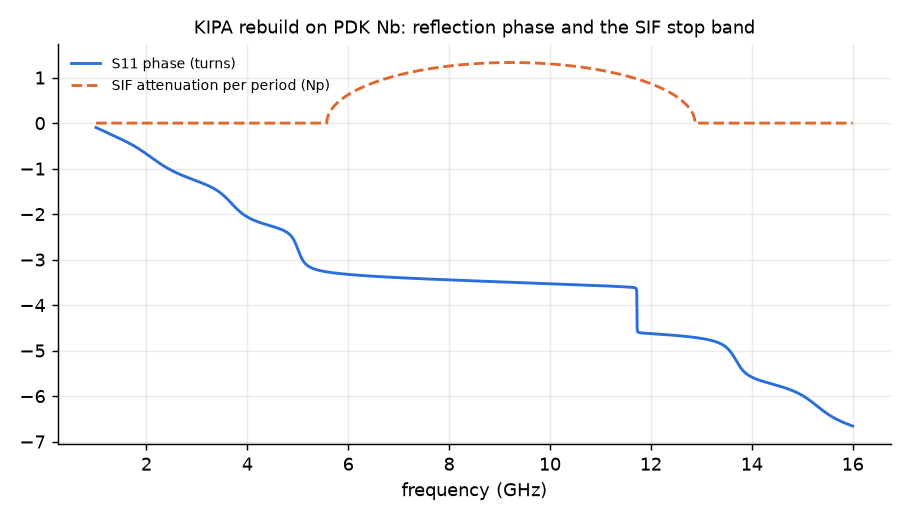

SIF stop band (attenuation > 0.5 Np/period): 5.84–12.61 GHz; resonance in it at 11.723 GHz, κ/2π ≈ 2.82 MHz (Q_ext ≈ 4.16e+03) on Nb.

In [9]:
f = np.linspace(1e9, 16e9, 30001)
def tl(freq, a, b, length_um):
    q = cpw_properties(7.0, a, b, PDK.name)
    bl = 2 * np.pi * freq / q["vp_m_s"] * length_um * 1e-6
    z = q["Z0_ohm"]
    m = np.zeros(freq.shape + (2, 2), dtype=complex)
    m[..., 0, 0] = m[..., 1, 1] = np.cos(bl)
    m[..., 0, 1] = 1j * z * np.sin(bl)
    m[..., 1, 0] = 1j * np.sin(bl) / z
    return m, q
chain, rows = [], []
for name, a, b, _ in SECTIONS:
    m, q = tl(f, a, b, lengths[name])
    chain.append(m)
    rows.append([name, f"{a}/{b}", q["Z0_ohm"], q["alpha_k"], lengths[name]])
m_res, q_res = tl(f, *RES[:2], lengths["RES"])
m_w, q_w = tl(f, *WIRE[:2], lengths["WIRE"])
rows += [["RES", "5/15", q_res["Z0_ohm"], q_res["alpha_k"], lengths["RES"]],
         ["WIRE", "1/10", q_w["Z0_ohm"], q_w["alpha_k"], lengths["WIRE"]]]
show_md(table_md(["section", "a/b (µm)", "Z0 (Ω)", "α_k", "length (µm)"], rows))
total = amp.cascade(*chain, m_res, m_w)
zin = total[..., 0, 1] / total[..., 1, 1]          # far end shorted: Z_in = B / D
s11 = (zin - 50) / (zin + 50)
period = amp.cascade(chain[0], chain[1])
att = amp.bloch(period).real
plot(OUT / "unsw_kipa_response.png", [(f / 1e9, np.degrees(np.unwrap(np.angle(s11))) / 360, "S11 phase (turns)"),
                                       (f / 1e9, att, "SIF attenuation per period (Np)", "--")],
     "frequency (GHz)", "", "KIPA rebuild on PDK Nb: reflection phase and the SIF stop band")
inside = att > 0.5
fr, kr = amp.resonance(f[inside], s11[inside]) if inside.any() else (float("nan"), float("nan"))
show_md(f"SIF stop band (attenuation > 0.5 Np/period): {f[inside][0] / 1e9:.2f}–{f[inside][-1] / 1e9:.2f} GHz; "
        f"resonance in it at {fr / 1e9:.3f} GHz, κ/2π ≈ {kr / 1e6:.3g} MHz (Q_ext ≈ {fr / kr:.3g}) on Nb.")

## 9 · FEM: send the jobs
A Q3D C-matrix job of the resonator + wire (the wire's capacitance and the taper parasitics); a driven S11 run of
the whole line is the right extraction for the SIF (not exported here). `RUN_FEM = False`.

In [10]:
jobs = export_sims(DESIGN, ["resonator"])
display(Markdown(jobs_md(jobs)))
if RUN_FEM:
    from quantcore_circuits.sim_tools import solve_job
    solve_job(jobs["resonator"][0])

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| resonator | `build/jobs/unsw_kipa_resonator_q3d_cmatrix` | 1 · waveguide · `T7.b`<br>2 · waveguide · `T8.a`<br>3 · waveguide · `T8.b`<br>4 · edge · `S6` | `T7.b`, `T8.b` |

## 10 · Bring it back

In [11]:
job = jobs["resonator"][0]
show_md("Results found" if (Path(job) / "results" / "results.json").exists() else
        f"No results in `{job}` yet: the section Z0 / v_p are the analytic CPW values.")

No results in `build\jobs\unsw_kipa_resonator_q3d_cmatrix` yet: the section Z0 / v_p are the analytic CPW values.

## 11 · Iterate: the resonator length
One property: the 5/15 µm resonator 2981 → 2500 µm (the resonance moves up inside the stop band).

In [12]:
m_res2, _ = tl(f, *RES[:2], lengths["RES"] - 481)
tot2 = amp.cascade(*chain, m_res2, m_w)
s2 = (tot2[..., 0, 1] / tot2[..., 1, 1] - 50) / (tot2[..., 0, 1] / tot2[..., 1, 1] + 50)
fr2, kr2 = amp.resonance(f[inside], s2[inside])
show_md(table_md(["resonator (µm)", "f_r (GHz)", "κ/2π (MHz)"],
                 [[lengths["RES"], fr / 1e9, kr / 1e6], [lengths["RES"] - 481, fr2 / 1e9, kr2 / 1e6]]))

| resonator (µm) | f_r (GHz) | κ/2π (MHz) |
|---|---|---|
| 2981 | 11.72 | 2.816 |
| 2500 | 12.52 | 15.07 |

## 12 · Build and export
`qcc build examples/designs/amplifiers/unsw_kipa.json`, `qcc mask …`.

In [13]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

cheese: build; written: M1 8448, M3 8448, CHIP_BOUNDARY 1, MARKERS_DICING 4, MARKERS_ALIGN 36

## 13 · Snapshots — the rebuild next to the original
The full rebuilt die; the end of the resonator and the 1 µm wire with its short; the original BA13 GDS (rendered
read-only from `build/external/kipa_zenodo_7600250/`).

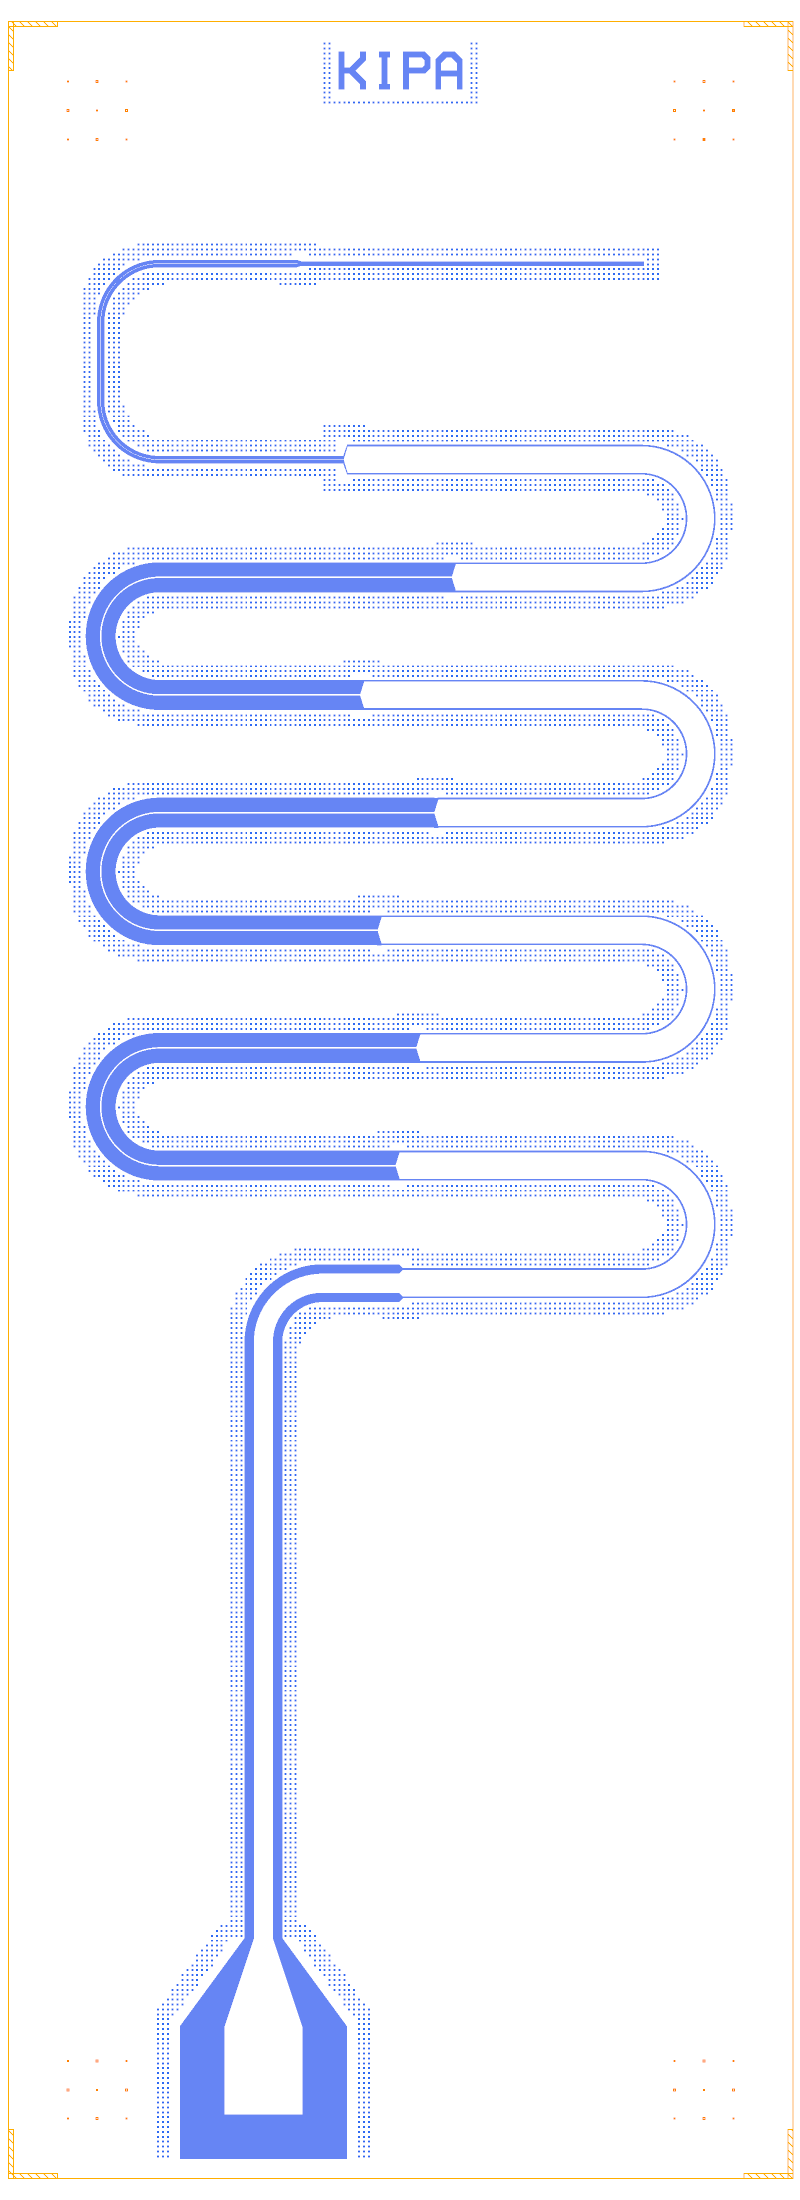

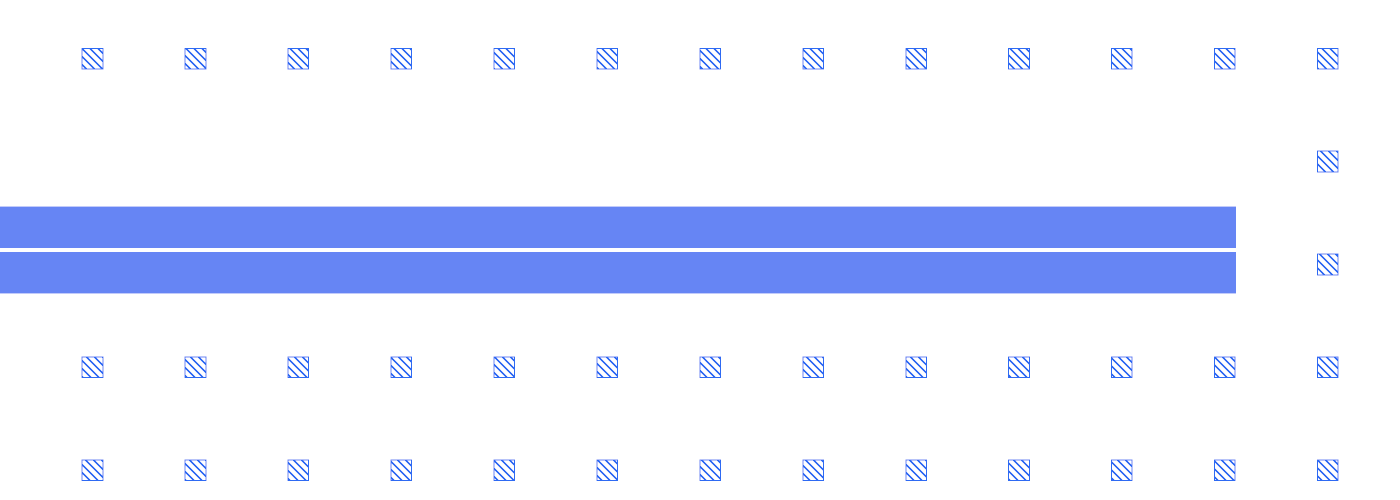

In [14]:
show_snapshot(d, OUT / "unsw_kipa.png", size=(800, 2200), width=300)
show_snapshot(d, OUT / "unsw_kipa_wire.png", box=(x_end - 300, y_w - 60, x_end + 40, y_w + 60), size=(1400, 500),
              width=560)
ref = ROOT / "build/external/kipa_zenodo_7600250/BA13_device_gds.GDS"
if ref.exists():
    from quantcore_circuits.live.snapshot import snapshot
    display(Image(filename=str(snapshot(str(ref), OUT / "unsw_kipa_original.png", size=(800, 2200))), width=300))

## 14 · Summary
* **Matches the source:** the section sequence (100/45 feed, 4 × 138/6 and 3 × 10/70 SIF sections, 5/15 resonator,
  1 µm wire shorted to ground) with the measured widths and lengths, the 4 × 11 mm die, the feed from the south.
* **Differs:** our serpentine (300 µm U-turns, tapers at the section boundaries), a Quantcore `BondPad` on the
  feed, the PDK Nb film instead of the source's kinetic film — on Nb the resonator is mostly geometric, so f_r and
  the nonlinearity differ from the device (its film is not in the GDS).
* **PDK design warnings:** none (no junctions).
* **Not modelled:** the 3WM gain (needs the film's I* and L_s: see `ki_twpa_serpentine` for the CME model), the
  donor spins.